# Optical TTF & LBWFS Simulation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from astropy.io import fits

# Constants for all simulations
rad_to_as = 3600 * 180 / np.pi
wvl = 0.775e-6 # TTF mean wavelength, m
D = 10.95 # telescope diameter, m
r0 = 0.16 # median seeing, m
strehl = 0.05 # Strehl at TTF wavelength (320 nm RMS HO WFE)
tts_bs = 0.90 # Transmission of beamsplitter cube to TTS
strap_cngn = 1.0 # STRAP centroid gain

In [2]:
# Current and tested cameras. Binned to 11 µm pixels, except STRAP. QE at 0.75 µm.
cameras = {
    "STRAP":        {"read_noise": 0.0,   "dark_curr": 0.000,   "qe": 0.50, },
    "KURO 1200B":   {"read_noise": 1.679, "dark_curr": 0.883,   "qe": 0.72, },
    "Prime 95B":    {"read_noise": 1.710, "dark_curr": 0.475,   "qe": 0.73, },
    "Marana-11":    {"read_noise": 1.565, "dark_curr": 0.637,   "qe": 0.72, },
    "QHY530":       {"read_noise": 1.1*4, "dark_curr": 0.001*16,"qe": 0.40, },
    "Aries 6504P":  {"read_noise": 0.43*2,"dark_curr": 0.01*4,  "qe": 0.60, },
    "Little Joe":   {"read_noise": 8.0,   "dark_curr": 5.000,   "qe": 0.65, },
    "Ideal":        {"read_noise": 0.0,   "dark_curr": 0.000,   "qe": 1.00, },
}

cams = {
    'Ideal':        {"read_noise": 0.0,    "dark_curr": 0.000,   "qe": 1.00},
    'Aries 6504P' : {"read_noise": 0.875,  "dark_curr": 0.050,   "qe": 0.60},
    'KURO 1200B' :  {"read_noise": 1.68,   "dark_curr": 0.883,   "qe": 0.72},
    'Prime 95B' :   {"read_noise": 1.71,   "dark_curr": 0.475,   "qe": 0.73},
    'Marana 11' :   {"read_noise": 1.596,  "dark_curr": 0.662,   "qe": 0.72},
}

## Functions to compute simulated images

In [3]:
def gaus2d_norm(x, y, x0, y0, sx, sy):
    """
    Generates a normalized 2D Gaussian function.

    Args:
        x (numpy.ndarray): X-coordinates of the grid.
        y (numpy.ndarray): Y-coordinates of the grid.
        x0 (float): Mean in the x-direction.
        y0 (float): Mean in the y-direction.
        sx (float): Standard deviation in the x-direction.
        sy (float): Standard deviation in the y-direction.

    Returns:
        numpy.ndarray: 2D array representing the Gaussian function.
    """
    z = (1. / (2. * np.pi * sx * sy)) * np.exp(-((x - x0)**2. / (2. * sx**2.) + (y - y0)**2. / (2. * sy**2.)))

    return  z

In [4]:
def psf_model(size, x0, y0, fwhm_dl, fwhm_sl, strehl):
    """
    Generates a simple 2-component Gaussian PSF.
    
    Args:
        size (tuple): Image array size (could be 3D)
        x0 (float): PSF x center, in pixels.
        y0 (float): PSF y center, in pixels.
        fwhm_dl (float): FWHM of diffraction-limited component, in pixels.
        fwhm_sl (float): FWHM of seeing-limited components, in pixels.
        strehl (float): Flux ratio of diffraction-limited component.

    Returns:
        numpy.ndarray: 2D or 3D array of PSFs
    """
    
    fw_to_sig = 1 / (2 * np.sqrt(2 * np.log(2)))

    x = np.arange(size[0])
    y = np.arange(size[1])
    X, Y = np.meshgrid(x, y)

    psf_dl = gaus2d_norm(X, Y, x0=x0, y0=y0, sx=fwhm_dl*fw_to_sig, sy=fwhm_dl*fw_to_sig)
    psf_sl = gaus2d_norm(X, Y, x0=x0, y0=y0, sx=fwhm_sl*fw_to_sig, sy=fwhm_sl*fw_to_sig)
    psf = strehl * psf_dl + (1. - strehl) * psf_sl
    
    psf = psf / np.sum(psf) # KLUDGE! Will over-estimate photometry if image size < seeing disk

    if len(size) > 2:
        psf = np.repeat(psf[:,:,np.newaxis], size[2], axis=2)
    
    return psf

In [5]:
def image_sim(size, x0, y0, fwhm_dl, fwhm_sl, strehl, read_noise, psf_flux, bkg_flux):
    """
    Generate a set of noisy simulated images.
    
    Args:
        size (tuple): Image array size (could be 3D)
        x0 (float): PSF x center, in pixels.
        y0 (float): PSF y center, in pixels.
        fwhm_dl (float): FWHM of diffraction-limited component, in pixels.
        fwhm_sl (float): FWHM of seeing-limited components, in pixels.
        strehl (float): Flux ratio of diffraction-limited image component.
        read_noise (float): Readout noise 1-sigma value (e-)
        psf_flux (float): Number of detected photons in PSF
        bkg_flux (float): Number of detected photons PER PIXEL on background

    Returns:
        numpy.ndarray: 2D or 3D array of simulated images
    """

    psf = psf_model(size, x0, y0, fwhm_dl, fwhm_sl, strehl)
    det_image = np.random.poisson(psf*psf_flux)
    det_bkg = np.random.poisson(np.full(size, bkg_flux))
    det_noise = np.random.normal(scale=read_noise, size=size)

    return (det_image + det_bkg) + det_noise

## Centroiding Algorithms

In [6]:
def cog(img, weight):
    """
    Compute weighted center-of-gravity over a stack of images.

    Args:
        img (ndarray): (x,y,N) stack of images
        weight (ndarray): (x,y) or (x,y,N) weights to give pixels

    Returns:
        float: X and Y centroid vectors, in pixels.
    """

    # Create coordinate arrays
    y, x = np.mgrid[0:img.shape[0], 0:img.shape[1]]
    xx = np.repeat(x[:,:,np.newaxis], img.shape[2], axis=2)
    yy = np.repeat(y[:,:,np.newaxis], img.shape[2], axis=2)

    # Create weight array
    if weight.ndim < 3:
        ww = np.repeat(weight[:,:,np.newaxis], img.shape[2], axis=2)
    else:
        ww = weight

    # Compute CoG
    x_cent = np.sum(img * xx * ww, axis=(0,1)) / np.sum(img * ww, axis=(0,1))
    y_cent = np.sum(img * yy * ww, axis=(0,1)) / np.sum(img * ww, axis=(0,1))

    return x_cent, y_cent

In [7]:
def gauss_xcor(img, fwhm, ref=None):
    """
    Compute centroid using a cross-correlation with a Gaussian (follows eval_subimage_disp.pro)

    Args:
        img (ndarray): (x,y,N) stack of images
        fwhm (float): Expected FWHM of spot in pixels
        ref (ndarray): (x, y) reference image. Default is None. Clobbers fwhm if provided.

    Returns:
        float: X and Y centroid vectors.
    """

    fw_to_sig = 1 / (2 * np.sqrt(2 * np.log(2)))
    x0 = img.shape[0]/2 - 0.5
    y0 = img.shape[1]/2 - 0.5

    # Calculate reference image if not given
    if ref is None:
        x = np.arange(img.shape[0])
        y = np.arange(img.shape[1])
        X, Y = np.meshgrid(x, y)
        ref = gaus2d_norm(X, Y, x0=x0, y0=y0, sx=fwhm*fw_to_sig, sy=fwhm*fw_to_sig)
    fft_ref = np.conjugate(np.fft.fft2(ref))
    fft_ref[0,0]=0. # Remove DC term

    x_cent = np.zeros(img.shape[2])
    y_cent = np.zeros(img.shape[2])
    maxcor = np.zeros(img.shape[2])
    for i in np.arange(img.shape[2]):
        ccFT = fft_ref * np.fft.fft2(img[:,:,i])
        cc = np.fft.ifft2(ccFT).real
        maxcc = np.max(cc)
        xloc, yloc = np.unravel_index(np.argmax(cc), cc.shape)
    
        m1_xloc = xloc - 1
        p1_xloc = xloc + 1
        m1_yloc = yloc - 1
        p1_yloc = yloc + 1
      
        if xloc == 0: m1_xloc = img.shape[0]-1
        if xloc == img.shape[0]-1: p1_xloc = 0
        if yloc == 0: m1_yloc = img.shape[1]-1
        if yloc == img.shape[1]-1: p1_yloc = 0
    
        cc0 = cc[xloc,yloc]
        ccm1x = cc[m1_xloc,yloc]
        ccp1x = cc[p1_xloc,yloc]
        delx = -0.5*(ccm1x-ccp1x)/(ccm1x+ccp1x-2.0*cc0)
        ccm1y = cc[xloc,m1_yloc]
        ccp1y = cc[xloc, p1_yloc]
        dely = -0.5*(ccm1y-ccp1y)/(ccm1y+ccp1y-2.0*cc0)
    
        estx = delx - xloc + img.shape[0]
        esty = dely - yloc + img.shape[1]
    
        if estx > img.shape[0]/2.: estx = estx - img.shape[0]
        if estx < -img.shape[0]/2.: estx = estx + img.shape[0]
        if esty > img.shape[1]/2.: esty = esty - img.shape[1]
        if esty < -img.shape[1]/2.: esty = esty + img.shape[1]
    
        x_cent[i] = x0-esty # Not sure why X and Y are flipped!
        y_cent[i] = y0-estx

    return x_cent, y_cent #, ref, cc

## Photometry Calculation

In [42]:
# Zero point taken from https://paulmartini.github.io/useful-data/
def calc_flux(mag):
    
    zero_pt_I = 452.0e10 # photons/cm^2/s/m
    area = 72 * 1e2**2 # cm^2
    bandwidth = 0.15e-6 # m
    throughput = 0.9 * 0.5 # 90% atm/50% optics

    return zero_pt_I * area * bandwidth * throughput * 10 ** (-mag / 2.5)

In [43]:
# Photometry (DAVINCI zeropoints from KAON 764)
# The detector quantum efficiencies used ... are the minimum for a Hawaii-4RG detector (Adkins, 2009a).
def opt_phot(mag):
    """
    Compute photon flux at detector

    Args:
        mag (float): Star magnitude in I/Z 

    Returns:
        float: Photon flux at detector (photons/s)
    """

    zpt_I = 27.34 # I band (700-854 nm) photometric zeropoint
    zpt_Z = 27.16 # Z band (855-962 nm) photometric zeropoint
    qe = 0.70 # TBC
    phot_I = 10 ** (-0.4 * (mag-zpt_I)) / qe
    phot_Z = 10 ** (-0.4 * (mag-zpt_Z)) / qe

    return phot_I + phot_Z

def opt_bkg():
    """
    Compute sky photon flux at detector

    Args:
        none

    Returns:
        float: Photon flux at detector (photons/s/arcsec^2)
    """

    bkg_I = 19.33 # I band (700-854 nm) sky brightness
    bkg_Z = 18.45 # Z band (855-962 nm) sky brightness
    zpt_I = 27.34 # I band (700-854 nm) photometric zeropoint
    zpt_Z = 27.16 # Z band (855-962 nm) photometric zeropoint
    qe = 0.70 # TBC
    phot_I = 10 ** (-0.4 * (bkg_I-zpt_I)) / qe
    phot_Z = 10 ** (-0.4 * (bkg_Z-zpt_Z)) / qe

    return phot_I + phot_Z

In [44]:
f1 = calc_flux(18)
f2 = opt_phot(18)
print((f1, f2))

(13860.366177665295, 14368.860391468586)


## Testing TT Functionality

In [85]:
def add_noise(n_stack, image, pxscl, texp, mag, camera, bs, debug=False):

    read_noise = camera['read_noise'] # e-/frame
    dark_current = camera['dark_curr'] # e-/s/pix
    qe = camera['qe'] # e-/photon
    
    flux_psf = opt_phot(mag) * bs * texp # phot/s
    flux_sky = opt_bkg() * bs # phot/s/arcsec^2
    flux_sky *= pxscl ** 2 # phot/s


    noisy_imgs = np.repeat(image[:, :, np.newaxis], repeats=n_stack, axis=2)
    noisy_imgs = noisy_imgs * flux_psf
    noisy_imgs += np.ones_like(noisy_imgs) * ((dark_current + flux_sky) * texp)

    noisy_imgs = np.random.poisson(noisy_imgs).astype('float64')
    noisy_imgs += np.random.normal(scale=read_noise, size=noisy_imgs.shape)

    if debug:
        print(f'PSF flux: {flux_psf:.2f} photons')
        print(f'Sky flux: {flux_sky:.2f} photons/pix')
        box_sum = noisy_imgs[:, :, 100].sum()
        print(f'Image Sum (16x16): {box_sum.mean():.2f}')

    return noisy_imgs

Mag:   [10.5 11.5 12.5 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5]
LUT:   [1000 1000 1000 1000  500  250  125   75   50   25   25]
Model: [1000  707  500  353  250  176  125   88   62   44   31]


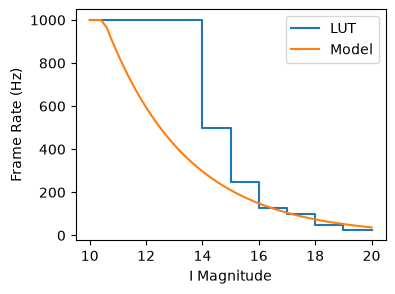

In [126]:
# Create model for TTF framerate lookup
strap_lut = np.array([[10,1000], [11,1000], [12,1000], [13,1000], \
                    [14, 500], [15, 250], [16, 125], [17, 75], \
                    [18,  50], [19,  25], [20,  25]])
strap_lut_plt = np.array([[10,1000], [14,1000], [14,500], [15,500], \
                    [15, 250], [16,250], [16, 125], [17, 125], [17, 100], [18, 100], \
                    [18,  50], [19, 50], [19,  25], [20, 25]])

def strap_frrt(mag):
    # frrt = np.clip(1000 * 4**(-0.5*(mag-13.5)), 25, 1000)
    frrt = np.clip(1000 * 4**(-0.25*(mag-10.5)), 25, 1000)
    return frrt

print(f"Mag:   {strap_lut[:,0]+0.5}")
print(f"LUT:   {strap_lut[:,1]}")
print(f"Model: {strap_frrt(strap_lut[:,0]+0.5).astype(int)}")

mag_vec = np.linspace(10,20,51)
plt.figure(figsize=(4, 3))
plt.plot(strap_lut_plt[:,0], strap_lut_plt[:,1], label="LUT")
plt.plot(mag_vec, strap_frrt(mag_vec), label="Model")
plt.xlabel("I Magnitude")
plt.ylabel("Frame Rate (Hz)")
plt.legend()
plt.show()

In [87]:
stack = np.zeros((16, 16, 1000))
for i in range(1000):
    stack[:, :, i] = fits.getdata(f'./data/to_aries/im_{i + 1:04d}.fits')
long_exp = np.sum(stack, axis=2) / 1000

camera = 'Aries 6504P'
pxscl = 0.169 # arcsec/pix
fov = long_exp.shape[0] * pxscl # arcsec

mag = 18.5
frate = 30

stack_noisy = add_noise(1000, long_exp, pxscl, 1/frate, mag, cams[camera], bs=0.9, debug=True)

PSF flux: 271.98 photons
Sky flux: 170.66 photons/pix
Image Sum (16x16): 1551.98


In [55]:
ref = psf_model(size=(16, 16), x0=16/2-0.5, y0=16/2-0.5, 
                fwhm_dl=(rad_to_as * wvl / D) / pxscl,
                fwhm_sl=(rad_to_as * 0.98 * 0.5e-6 / r0) / pxscl,
                strehl=0.01)

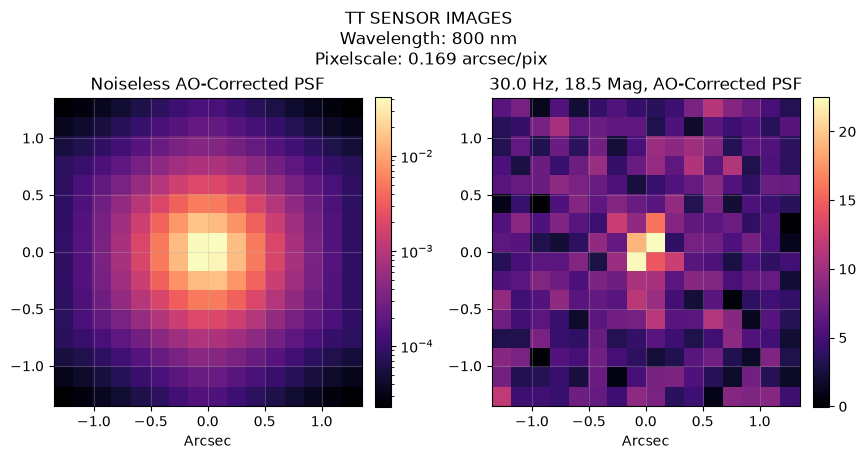

In [88]:
ind = 100

plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(long_exp, norm='log', cmap='magma', extent=[-fov/2, fov/2, -fov/2, fov/2])
plt.colorbar(fraction=0.046, pad=0.04)
plt.title('Noiseless AO-Corrected PSF')
plt.xlabel('Arcsec')
plt.grid(alpha=0.3)

plt.subplot(122)
plt.imshow(stack_noisy[:, :, ind],  cmap='magma', extent=[-fov/2, fov/2, -fov/2, fov/2])
plt.colorbar(fraction=0.046, pad=0.04)
plt.title(f'{frate:.1f} Hz, {mag:.1f} Mag, AO-Corrected PSF')
plt.xlabel('Arcsec')
plt.grid(alpha=0.3)

plt.suptitle(f'TT SENSOR IMAGES\nWavelength: 800 nm\n Pixelscale: {pxscl:.3f} arcsec/pix')
plt.subplots_adjust(wspace=0.3)

In [89]:
x0 = long_exp.shape[0]/2 - 0.5
y0 = long_exp.shape[1]/2 - 0.5

fw_seeing = ((0.5e-6 / r0) * rad_to_as * 0.98)
fw_diff = ((wvl / D) * rad_to_as)
x = np.linspace(-fov/2, fov/2, long_exp.shape[0])
x, y = np.meshgrid(x, x)
r = np.sqrt(x ** 2 + y ** 2)
w_seeing = r <= np.clip(fw_seeing / 2, (1. * pxscl) ** 0.5 / 2, None)
w_diff = r <= np.clip(fw_diff / 2, (1. * pxscl) ** 0.5 / 2, None)

w_ones = np.ones(long_exp.shape)

# Straight CoG
x_cent, y_cent = cog(stack_noisy, w_ones)
x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
print(f"CoG error (arcsec): ({x_err:.5f}, {y_err:.5f})")

# CoG with seeing limited circular mask
x_cent, y_cent = cog(stack_noisy, w_seeing)
x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
print(f"r < seeing mask (arcsec): ({x_err:.5f}, {y_err:.5f})")

# CoG with diffraction limited circular mask
x_cent, y_cent = cog(stack_noisy, w_diff)
x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
print(f"r < diff mask (arcsec): ({x_err:.5f}, {y_err:.5f})")

# CoG weighted by known PSF
w_psf = ref
x_cent, y_cent = cog(stack_noisy, w_psf)
x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
print(f"Weighted by PSF (arcsec): ({x_err:.5f}, {y_err:.5f})")

CoG error (arcsec): (0.02038, 0.02011)
r < seeing mask (arcsec): (0.01330, 0.01290)
r < diff mask (arcsec): (0.01113, 0.01099)
Weighted by PSF (arcsec): (0.01083, 0.01008)


Diffraction-limited FWHM=0.015 arcsec, Seeing-limited FWHM=0.632 arcsec
Star flux=163.2 ph, Background flux=2.7 ph/pix
PSF sum=1.0, Image sum=867.4
CoG error (arcsec): (0.026, 0.025)
r<FW_SL mask (arcsec): (0.015, 0.015)
Weighted by PSF (arcsec): (0.012, 0.012)


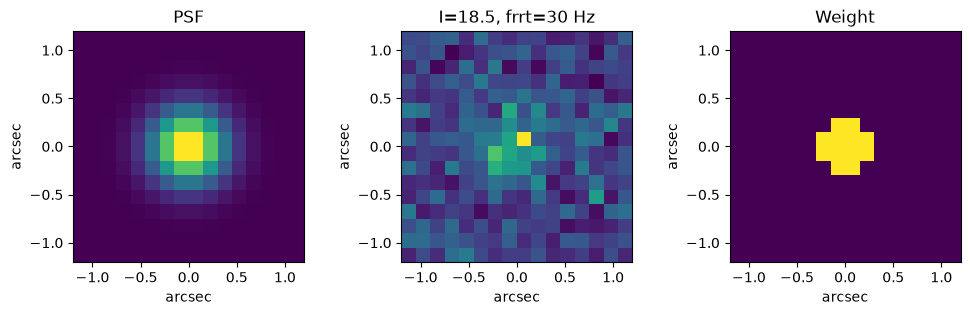

In [54]:
# Test functions so far...
# Define inputs
camera = "Aries 6504P"
size = (16,16,1000)
pscl = 0.15 # arcsec/pixel
frrt = 30. # Hz
qe = cameras[camera]["qe"] * tts_bs
read_noise = cameras[camera]["read_noise"]
mag = 18.5
psf_flux = opt_phot(mag) * qe / frrt # photons/frame
bkg_flux = opt_bkg() * qe * pscl**2 / frrt # photons/pixel

x0 = size[0]/2 - 0.5
y0 = size[1]/2 - 0.5

fw_dl = (rad_to_as * wvl / D) / pscl
fw_sl = (rad_to_as * 0.98 * 0.5e-6 / r0) / pscl
print(f"Diffraction-limited FWHM={fw_dl*pscl:.3f} arcsec, Seeing-limited FWHM={fw_sl*pscl:.3f} arcsec")
print(f"Star flux={psf_flux:.1f} ph, Background flux={bkg_flux:0.1f} ph/pix")

# Compute PSF and simulated images
psf = psf_model(size, x0, y0, fw_dl, fw_sl, strehl)
img = image_sim(size, x0, y0, fw_dl, fw_sl, strehl, read_noise, psf_flux, bkg_flux)
print(f"PSF sum={np.sum(psf[:,:,0]):.1f}, Image sum={np.sum(img[:,:,0]):.1f}")

# Straight CoG
w_ones = np.ones(size)
x_cent, y_cent = cog(img, w_ones)
x_err = pscl * (np.sum((x_cent - x0) ** 2.) / size[2]) ** 0.5
y_err = pscl * (np.sum((y_cent - y0) ** 2.) / size[2]) ** 0.5
print(f"CoG error (arcsec): ({x_err:.3f}, {y_err:.3f})")

# CoG with circular mask of diameter FWHM_SL
mask_radius = np.clip(1.0 * fw_sl / 2, 2**0.5, None)
Y, X = np.ogrid[:size[0], :size[1]]
r = (X - x0)**2 + (Y - y0)**2
w_circ = r <= mask_radius**2
x_cent, y_cent = cog(img, w_circ)
x_err = pscl * (np.sum((x_cent - x0) ** 2.) / size[2]) ** 0.5
y_err = pscl * (np.sum((y_cent - y0) ** 2.) / size[2]) ** 0.5
print(f"r<FW_SL mask (arcsec): ({x_err:.3f}, {y_err:.3f})")

# CoG weighted by known PSF
w_psf = psf
x_cent, y_cent = cog(img, w_psf)
x_err = pscl * (np.sum((x_cent - x0) ** 2.) / size[2]) ** 0.5
y_err = pscl * (np.sum((y_cent - y0) ** 2.) / size[2]) ** 0.5
print(f"Weighted by PSF (arcsec): ({x_err:.3f}, {y_err:.3f})")

# Display sample PSF, Image, and weight
x_min, x_max = -pscl*size[0]/2, pscl*size[0]/2
y_min, y_max = -pscl*size[1]/2, pscl*size[1]/2
fig, axes = plt.subplots(1, 3, figsize=(12,3))
plt.rcParams.update({'font.size': 10})
axes[0].imshow(psf[:,:,0], extent=[x_min, x_max, y_min, y_max], origin='lower')
axes[0].set_title("PSF")
axes[0].set_xlabel("arcsec")
axes[0].set_ylabel("arcsec")

axes[1].imshow(img[:,:,0], extent=[x_min, x_max, y_min, y_max], origin='lower')
axes[1].set_title(f"I={mag:.1f}, frrt={frrt:.0f} Hz")
axes[1].set_xlabel("arcsec")
axes[1].set_ylabel("arcsec")

axes[2].imshow(w_circ, extent=[x_min, x_max, y_min, y_max], origin='lower')
axes[2].set_title("Weight")
axes[2].set_xlabel("arcsec")
axes[2].set_ylabel("arcsec")
plt.show()

## TT Centroid Error vs Mag

In [93]:
cams

{'Ideal': {'read_noise': 0.0, 'dark_curr': 0.0, 'qe': 1.0},
 'Aries 6504P': {'read_noise': 0.875, 'dark_curr': 0.05, 'qe': 0.6},
 'KURO 1200B': {'read_noise': 1.68, 'dark_curr': 0.883, 'qe': 0.72},
 'Prime 95B': {'read_noise': 1.71, 'dark_curr': 0.475, 'qe': 0.73},
 'Marana 11': {'read_noise': 1.596, 'dark_curr': 0.662, 'qe': 0.72}}

In [131]:
results_tt = {}

for c in cams:

    print('Analyzing ' + c + '...')

    cog_vanilla = np.zeros_like(mag_vec)
    cog_seeing = np.zeros_like(mag_vec)
    cog_diff = np.zeros_like(mag_vec)
    cog_psf = np.zeros_like(mag_vec)

    if c == 'Aries 6504P':
        folder = 'to_aries'
        pxscl = 0.169
    elif c == 'Marana 11':
        folder = 'to_marana'
        pxscl = 0.143
    else:
        folder = 'to_teledyne'
        pxscl = 0.143
    stack = np.zeros((16, 16, 1000))
    for i in range(1000):
        stack[:, :, i] = fits.getdata(f'./data/' + folder + f'/im_{i + 1:04d}.fits')
    long_exp = np.sum(stack, axis=2) / 1000
    if c == 'Ideal':
        long_exp /= long_exp.sum()

    ref = psf_model(size=(16, 16), x0=16/2-0.5, y0=16/2-0.5, 
                fwhm_dl=(rad_to_as * wvl / D) / pxscl,
                fwhm_sl=(rad_to_as * 0.98 * 0.5e-6 / r0) / pxscl,
                strehl=0.01)

    for i, mag in enumerate(mag_vec):

        print(f'     Mag {mag:.2f}', end='\r')
        
        frame_rate = strap_frrt(mag)
        stack_noisy = add_noise(10000, long_exp, pxscl, 1/frame_rate, mag, cams[c], 
                                bs=0.9, debug=False)

        # Straight CoG
        x_cent, y_cent = cog(stack_noisy, w_ones)
        x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        cog_vanilla[i] = np.sqrt(x_err ** 2 + y_err ** 2)

        # CoG with seeing limited circular mask
        x_cent, y_cent = cog(stack_noisy, w_seeing)
        x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        cog_seeing[i] = np.sqrt(x_err ** 2 + y_err ** 2)

        # CoG with diffraction limited circular mask
        x_cent, y_cent = cog(stack_noisy, w_diff)
        x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        cog_diff[i] = np.sqrt(x_err ** 2 + y_err ** 2)

        # CoG weighted by known PSF
        x_cent, y_cent = cog(stack_noisy, ref)
        x_err = pxscl * (np.sum((x_cent - x0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        y_err = pxscl * (np.sum((y_cent - y0) ** 2.) / stack_noisy.shape[2]) ** 0.5
        cog_psf[i] = np.sqrt(x_err ** 2 + y_err ** 2)

    results_tt.update({
        c : {
            'Full CoG' : cog_vanilla,
            'Seeing-Limited CoG' : cog_seeing,
            'Diffraction-Limited CoG' : cog_diff,
            'Reference PSF CoG' : cog_psf,
        }
    })

Analyzing Ideal...
Analyzing Aries 6504P...
Analyzing KURO 1200B...
Analyzing Prime 95B...
Analyzing Marana 11...


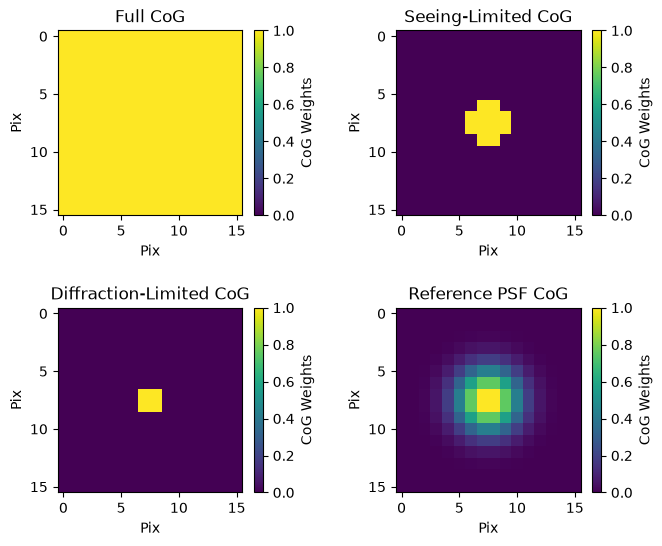

In [108]:
plt.figure(figsize=(8, 6))
plt.subplot(221)
plt.imshow(w_ones, vmin=0, vmax=1)
plt.colorbar(fraction=0.046, pad=0.04, label='CoG Weights')
plt.xlabel('Pix'); plt.ylabel('Pix')
plt.title('Full CoG')

plt.subplot(222)
plt.imshow(w_seeing, vmin=0, vmax=1)
plt.colorbar(fraction=0.046, pad=0.04, label='CoG Weights')
plt.xlabel('Pix'); plt.ylabel('Pix')
plt.title('Seeing-Limited CoG')

plt.subplot(223)
plt.imshow(w_diff, vmin=0, vmax=1)
plt.colorbar(fraction=0.046, pad=0.04, label='CoG Weights')
plt.xlabel('Pix'); plt.ylabel('Pix')
plt.title('Diffraction-Limited CoG')

plt.subplot(224)
plt.imshow(ref / ref.max(), vmin=0, vmax=1)
plt.colorbar(fraction=0.046, pad=0.04, label='CoG Weights')
plt.xlabel('Pix'); plt.ylabel('Pix')
plt.title('Reference PSF CoG')

plt.subplots_adjust(wspace=0.2, hspace=0.5)

In [115]:
rmag0 = 19.0 # Magnitude at which performance is normalized
fo_rmag0 = 50 # nm focus error at rmag0
fo_exp = 0.20 # exponent slope
fo_floor = 12.5 # nm floor focus error
tt_rmag0 = 40. # mas RMS focus error at rmag0
tt_exp = 0.43 # exponent slope
tt_floor = 2.5 # mas floor TT error

var_tt = np.clip(tt_rmag0**2 * 10**(tt_exp*(mag_vec-rmag0)), tt_floor**2, None)
var_fo = np.clip(fo_rmag0**2 * 10**(fo_exp*(mag_vec-rmag0)), fo_floor**2, None)

loop_gain = 0.5
err_tt = var_tt**0.5 / loop_gain
err_fo = var_fo**0.5 / loop_gain

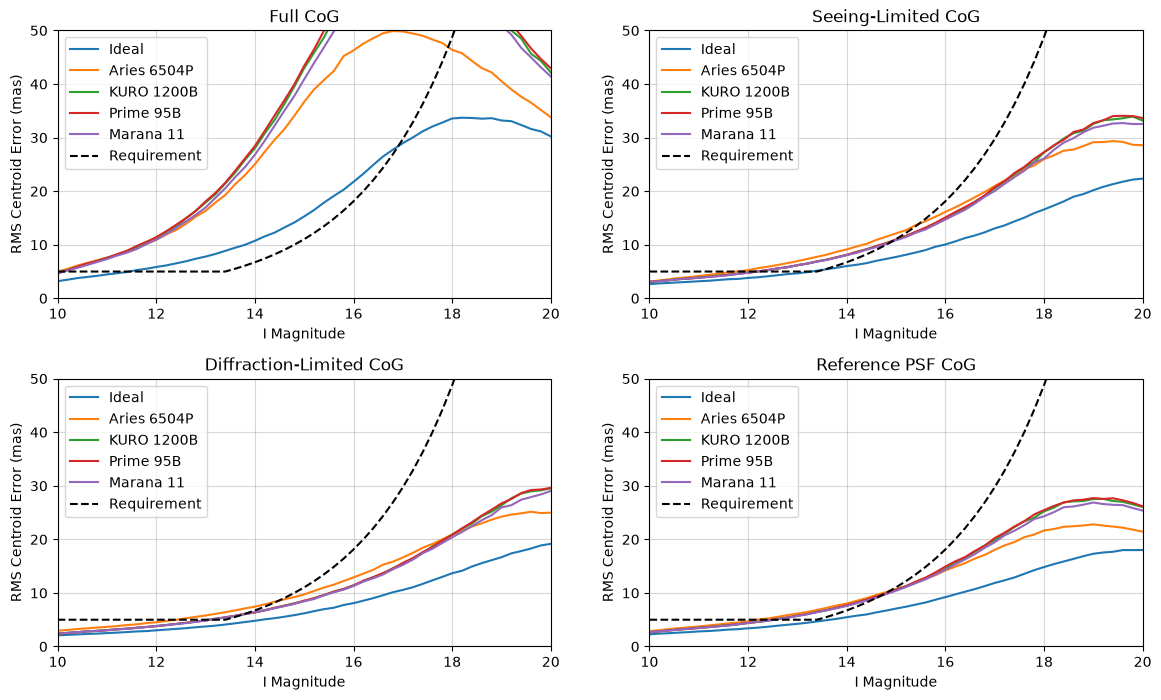

In [132]:
plt.figure(figsize=(14, 8))
for i, style in enumerate(results_tt['Ideal']):
    plt.subplot(2, 2, i + 1)
    for c in cams:
        plt.plot(mag_vec, results_tt[c][style] * 1e3, label=c)
    plt.plot(mag_vec, err_tt, label='Requirement', color='k', linestyle='dashed')
    plt.xlim([10, 20])
    plt.ylim([0, 50])
    plt.grid(alpha=0.5)
    plt.legend()
    plt.xlabel('I Magnitude')
    plt.ylabel('RMS Centroid Error (mas)')
    plt.title(style)
plt.subplots_adjust(hspace=0.3)

In [11]:
# Define function to compute centroid error (in arcsec) for a set of magnitudes.
def cent_err(size, mag_vec, pscl, cam, type="CoG", tts_bs=0.90):

    rad_to_as = 3600 * 180 / np.pi
    wvl = 0.8e-6 # TTF mean wavelength, m
    D = 10.0 # telescope diameter, m
    r0 = 0.15 # median seeing, m
    strehl = 0.05 # Strehl at TTF wavelength (320 nm RMS HO WFE)
    qe = cam["qe"] * tts_bs
    read_noise = cam["read_noise"]
    dark_curr = cam["dark_curr"]

    xc = size[0]/2-0.5
    yc = size[1]/2-0.5
    x0 = xc
    y0 = yc
    # Assume 0.1 pixel typical error
    # x0 = np.random.normal(scale=0.1, size=size[2])-0.5
    # y0 = np.random.normal(scale=0.1, size=size[2])-0.5

    fw_dl = (rad_to_as * wvl / D) / pscl
    fw_sl = (rad_to_as * 0.98 * 0.5e-6 / r0) / pscl

    match type:
        case "CoG":
            weight = np.ones(size)
        case "4x4":
            weight = np.zeros(size)
            weight[int(y0+0.5)-2:int(y0+0.5)+2, int(x0+0.5)-2:int(x0+0.5)+2] = 1.
        case "SL Mask":
            mask_radius = np.clip(fw_sl / 2, 2 ** 0.5, None)
            Y, X = np.ogrid[:size[0], :size[1]]
            r = (X - xc)**2 + (Y - yc)**2
            weight = r <= mask_radius**2
        case "DL Mask":
            mask_radius = np.clip(fw_dl / 2, 2 ** 0.5, None)
            Y, X = np.ogrid[:size[0], :size[1]]
            r = (X - xc)**2 + (Y - yc)**2
            weight = r <= mask_radius**2
        case "PSF":
            weight = psf_model(size, xc, yc, fw_dl, fw_sl, strehl)
    
    cent_err = np.zeros(len(mag_vec))
    for mag in mag_vec:
        frrt = strap_frrt(mag)
        psf_flux = opt_phot(mag) * qe / frrt
        bkg_flux = (opt_bkg() * qe * pscl**2 / frrt) + (dark_curr / frrt)

        img = image_sim(size, x0, y0, fw_dl, fw_sl, strehl, read_noise, psf_flux, bkg_flux)        
        x_cent, y_cent = cog(img, weight)
        x_err = pscl * (np.sum((x_cent - x0) ** 2.) / size[2]) ** 0.5
        y_err = pscl * (np.sum((y_cent - y0) ** 2.) / size[2]) ** 0.5
        cent_err[np.where(mag_vec == mag)] = (x_err**2 + y_err**2)**0.5

    return cent_err

In [12]:
# Evaluate STRAP performance vs. magnitude
size = (2,2,100000)
mag_vec = np.linspace(10, 20, 51)
err_strap = cent_err(size, mag_vec, 1.4, cameras["STRAP"], "SL Mask", tts_bs=0.90) * strap_cngn

pscl = 0.15
size = (32,32,10000)
err_cmos = cent_err(size, mag_vec, pscl, cameras["Aries 6504P"], "SL Mask", tts_bs=tts_bs)
err_ideal = cent_err(size, mag_vec, pscl, cameras["Ideal"], "SL Mask", tts_bs=tts_bs)

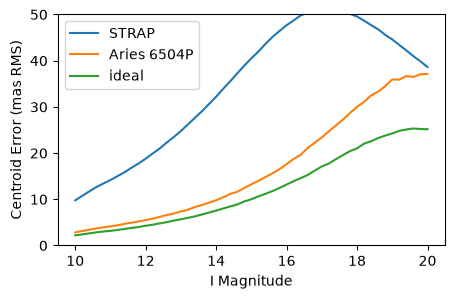

In [13]:
# Plot results
plt.figure(figsize=(5, 3))
plt.plot(mag_vec, 1e3*err_strap, label="STRAP")
plt.plot(mag_vec, 1e3*err_cmos, label="Aries 6504P")
plt.plot(mag_vec, 1e3*err_ideal, label="ideal")
plt.ylim(0,50)
plt.xlabel("I Magnitude")
plt.ylabel("Centroid Error (mas RMS)")
plt.legend()
plt.show()

## LBWFS

In [14]:
lb_mode = 20
lb_subaps = 304

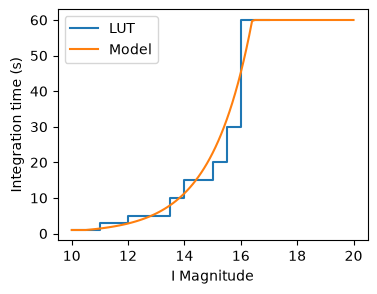

In [15]:
# Create model for LBWFS integration time lookup
lbwfs_lut = np.array([[10.0 ,1.], [11.0 ,1.], [11.0 ,3.], [12.0 ,3.], [12.0 ,5.], [13.5, 5.], \
                    [13.5, 10.], [14.0, 10.], [14.0, 15.], [15.0, 15.], [15.0, 20.], [15.5, 20.], \
                    [15.5, 30.], [16.0, 30.], [16.0, 60.], [17.0, 60.]])

def lbwfs_frrt(mag):
    frrt = np.clip(2**(1.0*(mag-10.5)), 1.0, 60.)
    #frrt = np.clip(2**(1.0*(mag-10.5)), 1.0, None)
    return frrt

#print(f"Mag:   {strap_lut[:,0]+0.5}")
#print(f"LUT:   {strap_lut[:,1]}")
#print(f"Model: {frrt_model(strap_lut[:,0]+0.5).astype(int)}")

mag_vec = np.linspace(10,20,101)
plt.figure(figsize=(4, 3))
plt.plot(lbwfs_lut[:,0], lbwfs_lut[:,1], label="LUT")
plt.plot(mag_vec, lbwfs_frrt(mag_vec), label="Model")
plt.xlabel("I Magnitude")
plt.ylabel("Integration time (s)")
plt.legend()
plt.show()

DL FWHM=0.330 arcsec, SL FWHM=0.674 arcsec, Convolved FWHM=0.750 arcsec
Star flux=877.3 ph, Background flux=231.8 ph/pix


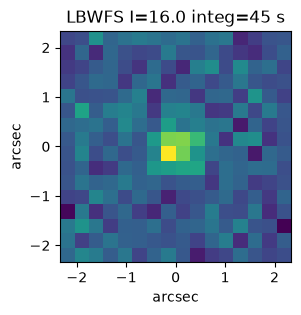

In [16]:
# Simulate typical LBWFS subap image
camera = "Little Joe"
size = (16,16,1)
pscl = 0.292 # arcsec/pixel
strehl = 0.0
qe = cameras[camera]["qe"] * (1-tts_bs)
read_noise = cameras[camera]["read_noise"]
dark_curr = cameras[camera]["dark_curr"]
mag = 16

x0 = size[0]/2-0.5
y0 = size[1]/2-0.5
fw_dl = (rad_to_as * wvl * lb_mode / D) / pscl
fw_sl = (rad_to_as * 0.98 * 0.5e-6 / r0) / pscl
fw_sl_conv = (fw_sl**2 + fw_dl**2) ** 0.5
print(f"DL FWHM={fw_dl*pscl:.3f} arcsec, SL FWHM={fw_sl*pscl:.3f} arcsec, Convolved FWHM={fw_sl_conv*pscl:.3f} arcsec")

integ = lbwfs_frrt(mag)
psf_flux = opt_phot(mag) * qe * integ / lb_subaps
bkg_flux = (opt_bkg() * qe * pscl**2 * integ / lb_subaps) + (dark_curr * integ)
print(f"Star flux={psf_flux:.1f} ph, Background flux={bkg_flux:0.1f} ph/pix")

img = image_sim(size, x0, y0, fw_dl, fw_sl_conv, strehl, read_noise, psf_flux, bkg_flux)        

x_min, x_max = -pscl*size[0]/2, pscl*size[0]/2
y_min, y_max = -pscl*size[1]/2, pscl*size[1]/2
plt.figure(figsize=(3, 3))
plt.imshow(img, extent=[x_min, x_max, y_min, y_max], origin='lower')
plt.title(f"LBWFS I={mag:.1f} integ={int(integ)} s")
plt.xlabel("arcsec")
plt.ylabel("arcsec")
plt.show()

## LBWFS summary plot vs. magnitude

In [17]:
# Define function to compute LBWFS centroid error for a set of magnitudes.
def cent_err_lbwfs(size, mag_vec, cam, lb_mode=20, tts_bs=0.90):

    rad_to_as = 3600 * 180 / np.pi
    wvl = 0.8e-6 # TTF mean wavelength, m
    D = 10.0 # telescope diameter, m
    r0 = 0.15 # median seeing, m
    strehl = 0. # Strehl at TTF wavelength (320 nm RMS HO WFE)
    pscl = 0.292 # arcsec/pixel
    qe = cam["qe"] * (1-tts_bs)
    read_noise = cam["read_noise"]
    dark_curr = cam["dark_curr"]

    if lb_mode == 20:
        lb_subaps = 304
    else:
        lb_subaps = 20

    x0 = size[0]/2-0.5
    y0 = size[1]/2-0.5
    fw_dl = (rad_to_as * wvl * lb_mode / D) / pscl
    fw_sl = (rad_to_as * 0.98 * 0.5e-6 / r0) / pscl
    fw_sl_conv = (fw_sl**2 + fw_dl**2) ** 0.5
    
    cent_err = np.zeros(len(mag_vec))
    for mag in mag_vec:
        if lb_mode == 20:
            lb_subaps = 304
            integ = lbwfs_frrt(mag)
        else:
            lb_subaps = 20
            integ = lbwfs_frrt(mag-1.5)
        psf_flux = opt_phot(mag) * qe * integ / lb_subaps
        bkg_flux = (opt_bkg() * qe * pscl**2 * integ / lb_subaps) + (dark_curr * integ)

        img = image_sim(size, x0, y0, fw_dl, fw_sl_conv, strehl, read_noise, psf_flux, bkg_flux)
        x_cent, y_cent = gauss_xcor(img, fw_sl_conv)
        x_err = pscl * (np.sum((x_cent - x0) ** 2.) / size[2]) ** 0.5
        y_err = pscl * (np.sum((y_cent - y0) ** 2.) / size[2]) ** 0.5
        cent_err[np.where(mag_vec == mag)] = (x_err**2 + y_err**2)**0.5

    return cent_err

In [18]:
# Evaluate various camera's performance vs. magnitude
size = (16,16,10000)
mag_vec = np.linspace(10, 20, 51)
err_lbwfs = cent_err_lbwfs(size, mag_vec, cameras["Little Joe"], tts_bs=0.90)
err_cmos = cent_err_lbwfs(size, mag_vec, cameras["Aries 6504P"], tts_bs=tts_bs)
err_ideal = cent_err_lbwfs(size, mag_vec, cameras["Ideal"], tts_bs=tts_bs)

In [19]:
err_lbwfs_5x5 = cent_err_lbwfs(size, mag_vec, cameras["Little Joe"], lb_mode=5, tts_bs=0.90)
err_cmos_5x5 = cent_err_lbwfs(size, mag_vec, cameras["Aries 6504P"], lb_mode=5, tts_bs=tts_bs)
err_ideal_5x5 = cent_err_lbwfs(size, mag_vec, cameras["Ideal"], lb_mode=5, tts_bs=tts_bs)

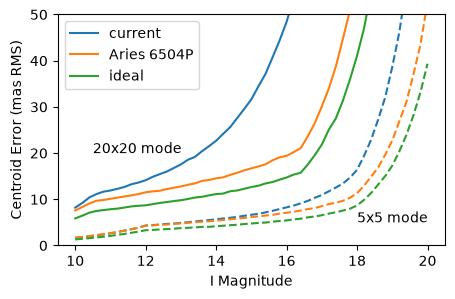

In [20]:
# Plot the results
plt.figure(figsize=(5, 3))
plt.plot(mag_vec, 1e3*err_lbwfs, label="current")
plt.plot(mag_vec, 1e3*err_cmos, label="Aries 6504P")
plt.plot(mag_vec, 1e3*err_ideal, label="ideal")
plt.plot(mag_vec, 1e3*err_lbwfs_5x5, color='#1f77b4', ls='--')
plt.plot(mag_vec, 1e3*err_cmos_5x5, color='#ff7f0e', ls='--')
plt.plot(mag_vec, 1e3*err_ideal_5x5, color='#2ca02c', ls='--')
plt.annotate("20x20 mode", xy=(10.5,20))
plt.annotate("5x5 mode", xy=(18,5))
plt.ylim(0,50)
plt.xlabel("I Magnitude")
plt.ylabel("Centroid Error (mas RMS)")
plt.legend()
plt.show()

## Camera comparisons

In [21]:
# Compare TTS cameras
size = (2,2,100000)
mag_vec = np.linspace(10, 20, 51)
err_tts_strap = cent_err(size, mag_vec, 1.4, cameras["STRAP"], "SL Mask", tts_bs=0.90)

pscl = 0.15
size = (32,32,10000)
err_tts_marana = cent_err(size, mag_vec, pscl, cameras["Marana-11"], "SL Mask", tts_bs=tts_bs)
err_tts_kuro = cent_err(size, mag_vec, pscl, cameras["KURO 1200B"], "SL Mask", tts_bs=tts_bs)
err_tts_prime95 = cent_err(size, mag_vec, pscl, cameras["Prime 95B"], "SL Mask", tts_bs=tts_bs)
err_tts_qhy530 = cent_err(size, mag_vec, pscl, cameras["QHY530"], "SL Mask", tts_bs=tts_bs)
err_tts_ariesp = cent_err(size, mag_vec, pscl, cameras["Aries 6504P"], "SL Mask", tts_bs=tts_bs)

KeyboardInterrupt: 

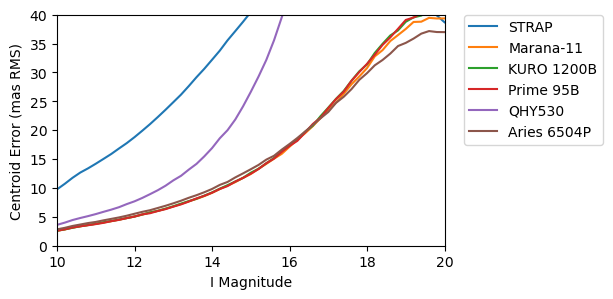

In [22]:
# Plot results
plt.figure(figsize=(5, 3))
plt.plot(mag_vec, 1e3*err_tts_strap, label="STRAP")
plt.plot(mag_vec, 1e3*err_tts_marana, label="Marana-11")
plt.plot(mag_vec, 1e3*err_tts_kuro, label="KURO 1200B")
plt.plot(mag_vec, 1e3*err_tts_prime95, label="Prime 95B")
plt.plot(mag_vec, 1e3*err_tts_qhy530, label="QHY530")
plt.plot(mag_vec, 1e3*err_tts_ariesp, label="Aries 6504P")

plt.xlim(10,20)
plt.ylim(0,40)
plt.xlabel("I Magnitude")
plt.ylabel("Centroid Error (mas RMS)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()

In [23]:
i = np.where(mag_vec == 18.0)
print("TTS centroid error at I=18.0")
print("Marana-11    ", np.array2string(1e3*err_tts_marana[i],precision=1))
print("KURO 1200B   ", np.array2string(1e3*err_tts_kuro[i],precision=1))
print("Prime 95B    ", np.array2string(1e3*err_tts_prime95[i],precision=1))
print("QHY530       ", np.array2string(1e3*err_tts_qhy530[i],precision=1))
print("Aries 6504P  ", np.array2string(1e3*err_tts_ariesp[i],precision=1))

TTS centroid error at I=18.0
Marana-11     [30.8]
KURO 1200B    [31.4]
Prime 95B     [31.5]
QHY530        [2470.]
Aries 6504P   [29.9]


In [24]:
# Compare LBWFS cameras
size = (16,16,10000)
mag_vec = np.linspace(10, 20, 51)
err_lb_joe = cent_err_lbwfs(size, mag_vec, cameras["Little Joe"], tts_bs=0.90)
err_lb_marana = cent_err_lbwfs(size, mag_vec, cameras["Marana-11"], tts_bs=tts_bs)
err_lb_kuro = cent_err_lbwfs(size, mag_vec, cameras["KURO 1200B"], tts_bs=tts_bs)
err_lb_prime95 = cent_err_lbwfs(size, mag_vec, cameras["Prime 95B"], tts_bs=tts_bs)
err_lb_qhy530 = cent_err_lbwfs(size, mag_vec, cameras["QHY530"], tts_bs=tts_bs)
err_lb_ariesp = cent_err_lbwfs(size, mag_vec, cameras["Aries 6504P"], tts_bs=tts_bs)

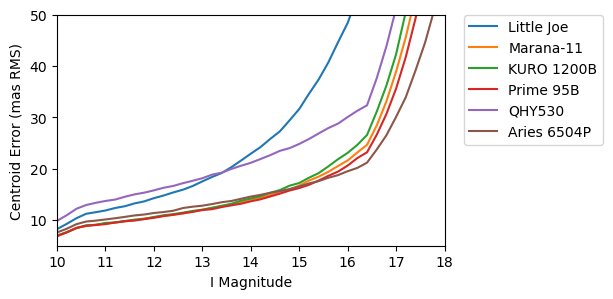

In [25]:
# Plot the results
plt.figure(figsize=(5, 3))
plt.plot(mag_vec, 1e3*err_lb_joe, label="Little Joe")
plt.plot(mag_vec, 1e3*err_lb_marana, label="Marana-11")
plt.plot(mag_vec, 1e3*err_lb_kuro, label="KURO 1200B")
plt.plot(mag_vec, 1e3*err_lb_prime95, label="Prime 95B")
plt.plot(mag_vec, 1e3*err_lb_qhy530, label="QHY530")
plt.plot(mag_vec, 1e3*err_lb_ariesp, label="Aries 6504P")
plt.xlim(10,18)
plt.ylim(5,50)
plt.xlabel("I Magnitude")
plt.ylabel("Centroid Error (mas RMS)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()

In [26]:
i = np.where(mag_vec == 17.0)
print("LBWFS 20x20 centroid error at I=17.0")
print("Little Joe   ", np.array2string(1e3*err_lb_joe[i],precision=1))
print("Marana-11    ", np.array2string(1e3*err_lb_marana[i],precision=1))
print("KURO 1200B   ", np.array2string(1e3*err_lb_kuro[i],precision=1))
print("Prime 95B    ", np.array2string(1e3*err_lb_prime95[i],precision=1))
print("QHY530       ", np.array2string(1e3*err_lb_qhy530[i],precision=1))
print("Aries 6504P  ", np.array2string(1e3*err_lb_ariesp[i],precision=1))

LBWFS 20x20 centroid error at I=17.0
Little Joe    [116.4]
Marana-11     [38.9]
KURO 1200B    [42.3]
Prime 95B     [35.6]
QHY530        [51.2]
Aries 6504P   [30.1]
